# Hackathon · Team 4 · Step 4: from a photo to the silhouette — and the whole app

The user draws the silhouette of the flat by hand, takes a photo, and types the area. A hand drawing is never clean: the lines are crooked, there are **gaps**, the paper has a **grid**, half of the photo is in **shadow**, and there may be **stray marks**. Step 4 turns this photo into the model's input. No new data, no training: only image processing.

| | What | How |
|---|---|---|
| 1 | the shadow goes | the photo is divided by its own blurred paper colour |
| 2 | pen lines, no grid | the pen is much darker than the grid: a threshold between the two (Otsu); small marks are dropped |
| 3 | the gaps close | the lines become 1 pixel wide; two line ends that are **close in space but far apart along the line** are joined (a hook or a small branch at a corner is not joined) |
| 4 | the closed shape | everything that cannot be reached from the border of the photo is inside |
| 5 | corners, squared | the outline is simplified to its corners, then every edge is made exactly horizontal or vertical |
| 6 | metres | the area the user typed gives the scale |
| 7 | the model's input | turned so the long side is horizontal, 128 × 128, exactly as in training |

**If no closed shape is found**, the app asks the user to **tap the corners** on the photo (section 5).

The code is in `layout_core.py` (`photo_to_outline`, `silhouette_input`, `design_from_photo`): the model server uses the same functions.

# 0. Setup

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
from matplotlib.patches import Patch

import layout_core as lc

DATA_DIR = Path("../../data")
FIG_DIR = Path("../figures")
MODEL_DIR = Path("../models") / "layout_generator"
EXAMPLES_DIR = Path("../layout_examples")
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")


def save_fig(name):
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")


config = json.loads((MODEL_DIR / "layout_cvae_config.json").read_text())
rules = json.loads((MODEL_DIR / "room_rules.json").read_text())
AREA_MEAN, AREA_STD = config["condition"]["area_mean"], config["condition"]["area_std"]
model = lc.LayoutCVAE(latent_dim=config["latent_dim"]).to(DEVICE)
model.load_state_dict(torch.load(MODEL_DIR / config["weights"], map_location=DEVICE))
model.eval()

cache = np.load(DATA_DIR / f"generator_maps_{lc.IMG}px.npz")
sils = cache["sil"]                                        # read once
lib = pd.read_csv(DATA_DIR / "generator_lib.csv")         # made by 05_layout_to_vector.ipynb
val_rows = np.where(lib["split"] == "val")[0]
LEGEND = [Patch(facecolor=lc.COLORS[t], edgecolor="#3d3d3a", label=t) for t in lc.ROOMS + ["wall", "window", "door", "entrance"]]
print(f"model loaded | {len(val_rows):,} validation silhouettes | device: {DEVICE}")

model loaded | 1,580 validation silhouettes | device: cpu


# 1. The example sketch, step by step

`layout_examples/sketch_example.jpg`: our hand drawing on squared paper, with a shadow and three gaps.

0.25 s | gaps closed: 3 | corners after squaring: 8 | the drawing was turned by 4.9°
Figure saved to ..\figures\60_photo_to_silhouette.png


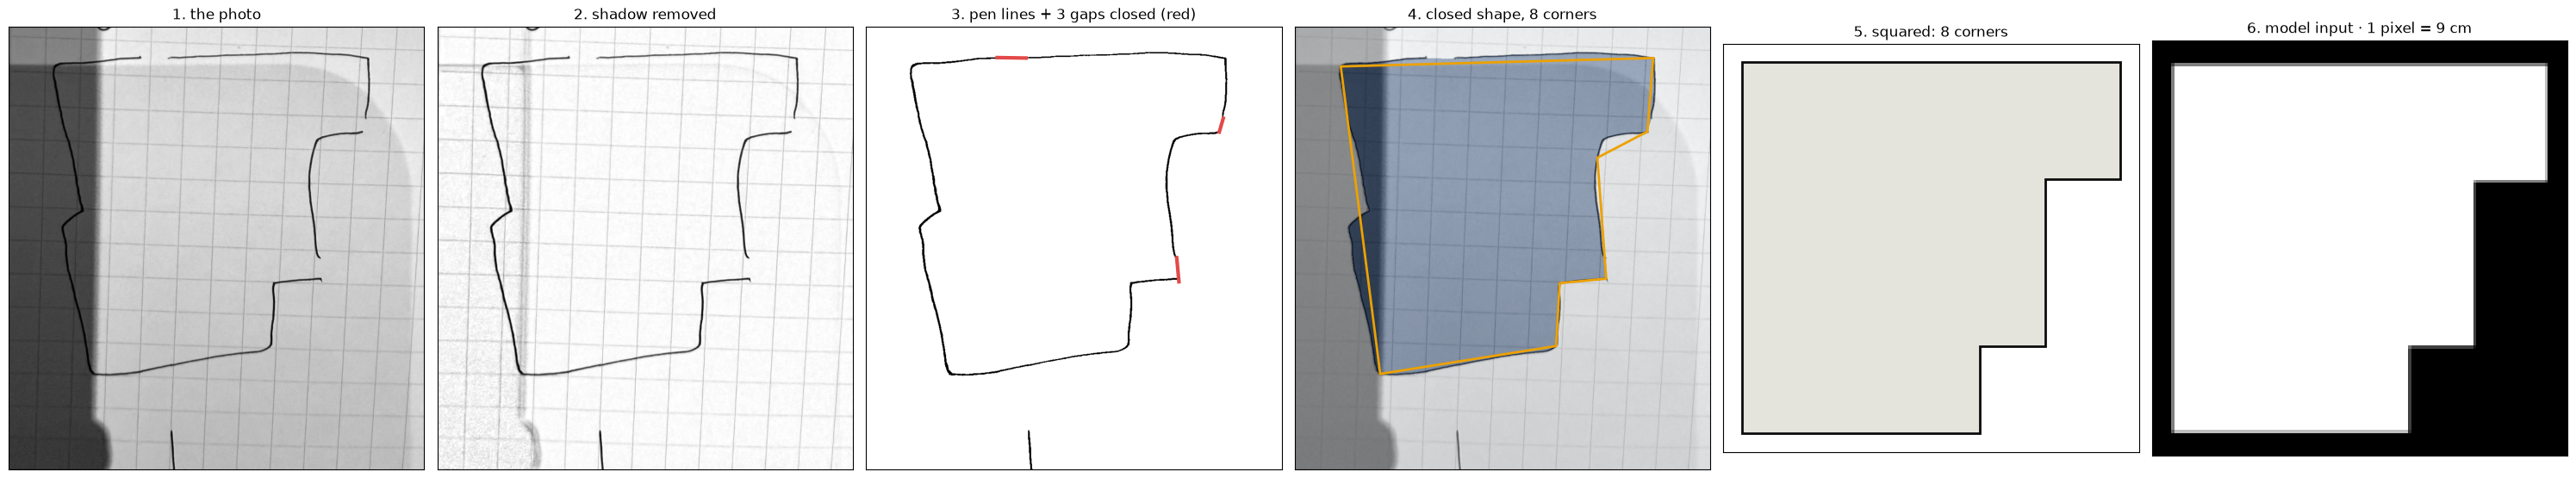

In [2]:
SKETCH = EXAMPLES_DIR / "sketch_example.jpg"
gray = lc.read_photo(SKETCH)
start = time.time()
corners, dbg = lc.photo_to_outline(gray, debug=True)
print(f"{time.time() - start:.2f} s | gaps closed: {len(dbg['links'])} | corners after squaring: {len(corners)} "
      f"| the drawing was turned by {np.degrees(dbg['theta']):.1f}°")
inp = lc.silhouette_input(corners, 95)

fig, axes = plt.subplots(1, 6, figsize=(30, 5.5))
axes[0].imshow(gray, cmap="gray"); axes[0].set_title("1. the photo", fontsize=12)
axes[1].imshow(dbg["flat"], cmap="gray"); axes[1].set_title("2. shadow removed", fontsize=12)
axes[2].imshow(dbg["ink"], cmap="gray_r")
for (x0, y0), (x1, y1) in dbg["links"]:
    axes[2].plot([x0, x1], [y0, y1], color="#e34948", linewidth=3)
axes[2].set_title(f"3. pen lines + {len(dbg['links'])} gaps closed (red)", fontsize=12)
axes[3].imshow(gray, cmap="gray"); axes[3].imshow(dbg["region"], alpha=0.35, cmap="Blues")
a = dbg["approx"]
axes[3].plot(*np.vstack([a, a[:1]]).T, color="#eda100", linewidth=2)
axes[3].set_title(f"4. closed shape, {len(a)} corners", fontsize=12)
axes[4].fill(*np.vstack([corners, corners[:1]]).T, facecolor="#e4e3dc", edgecolor="#0b0b0b", linewidth=2)
axes[4].set_aspect("equal"); axes[4].set_title(f"5. squared: {len(corners)} corners", fontsize=12)
axes[5].imshow(inp["sil_u8"], cmap="gray"); axes[5].set_title(f"6. model input · 1 pixel = {inp['m_per_px'] * 100:.0f} cm", fontsize=12)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
save_fig("60_photo_to_silhouette")
plt.show()

### What to look at
- Is the shadow gone, and the grid ignored? Are **all the gaps** closed, and only them?
- Does the squared outline keep the **steps** of the drawing? Small wiggles (smaller than about 1% of the outline's length) are dropped on purpose: a hand is never straight.

# 2. How reliable is it?

We cannot photograph 40 drawings, so we **make** them: 40 validation silhouettes are drawn like a hand sketch, with a crooked line, 1–3 gaps, a grid, a shadow, a tilt of up to 7°, and a stray mark. Then step 4 must find the silhouette again. We compare it with the true one (**IoU**, 1 = identical), allowing a turn or a mirror: an almost square flat can come out turned by 90°, and the model works the same.

shape found          1.000
IoU median           0.928
IoU >= 0.90          0.675
IoU >= 0.80          1.000
seconds per photo    0.400
Figure saved to ..\figures\61_photo_test.png


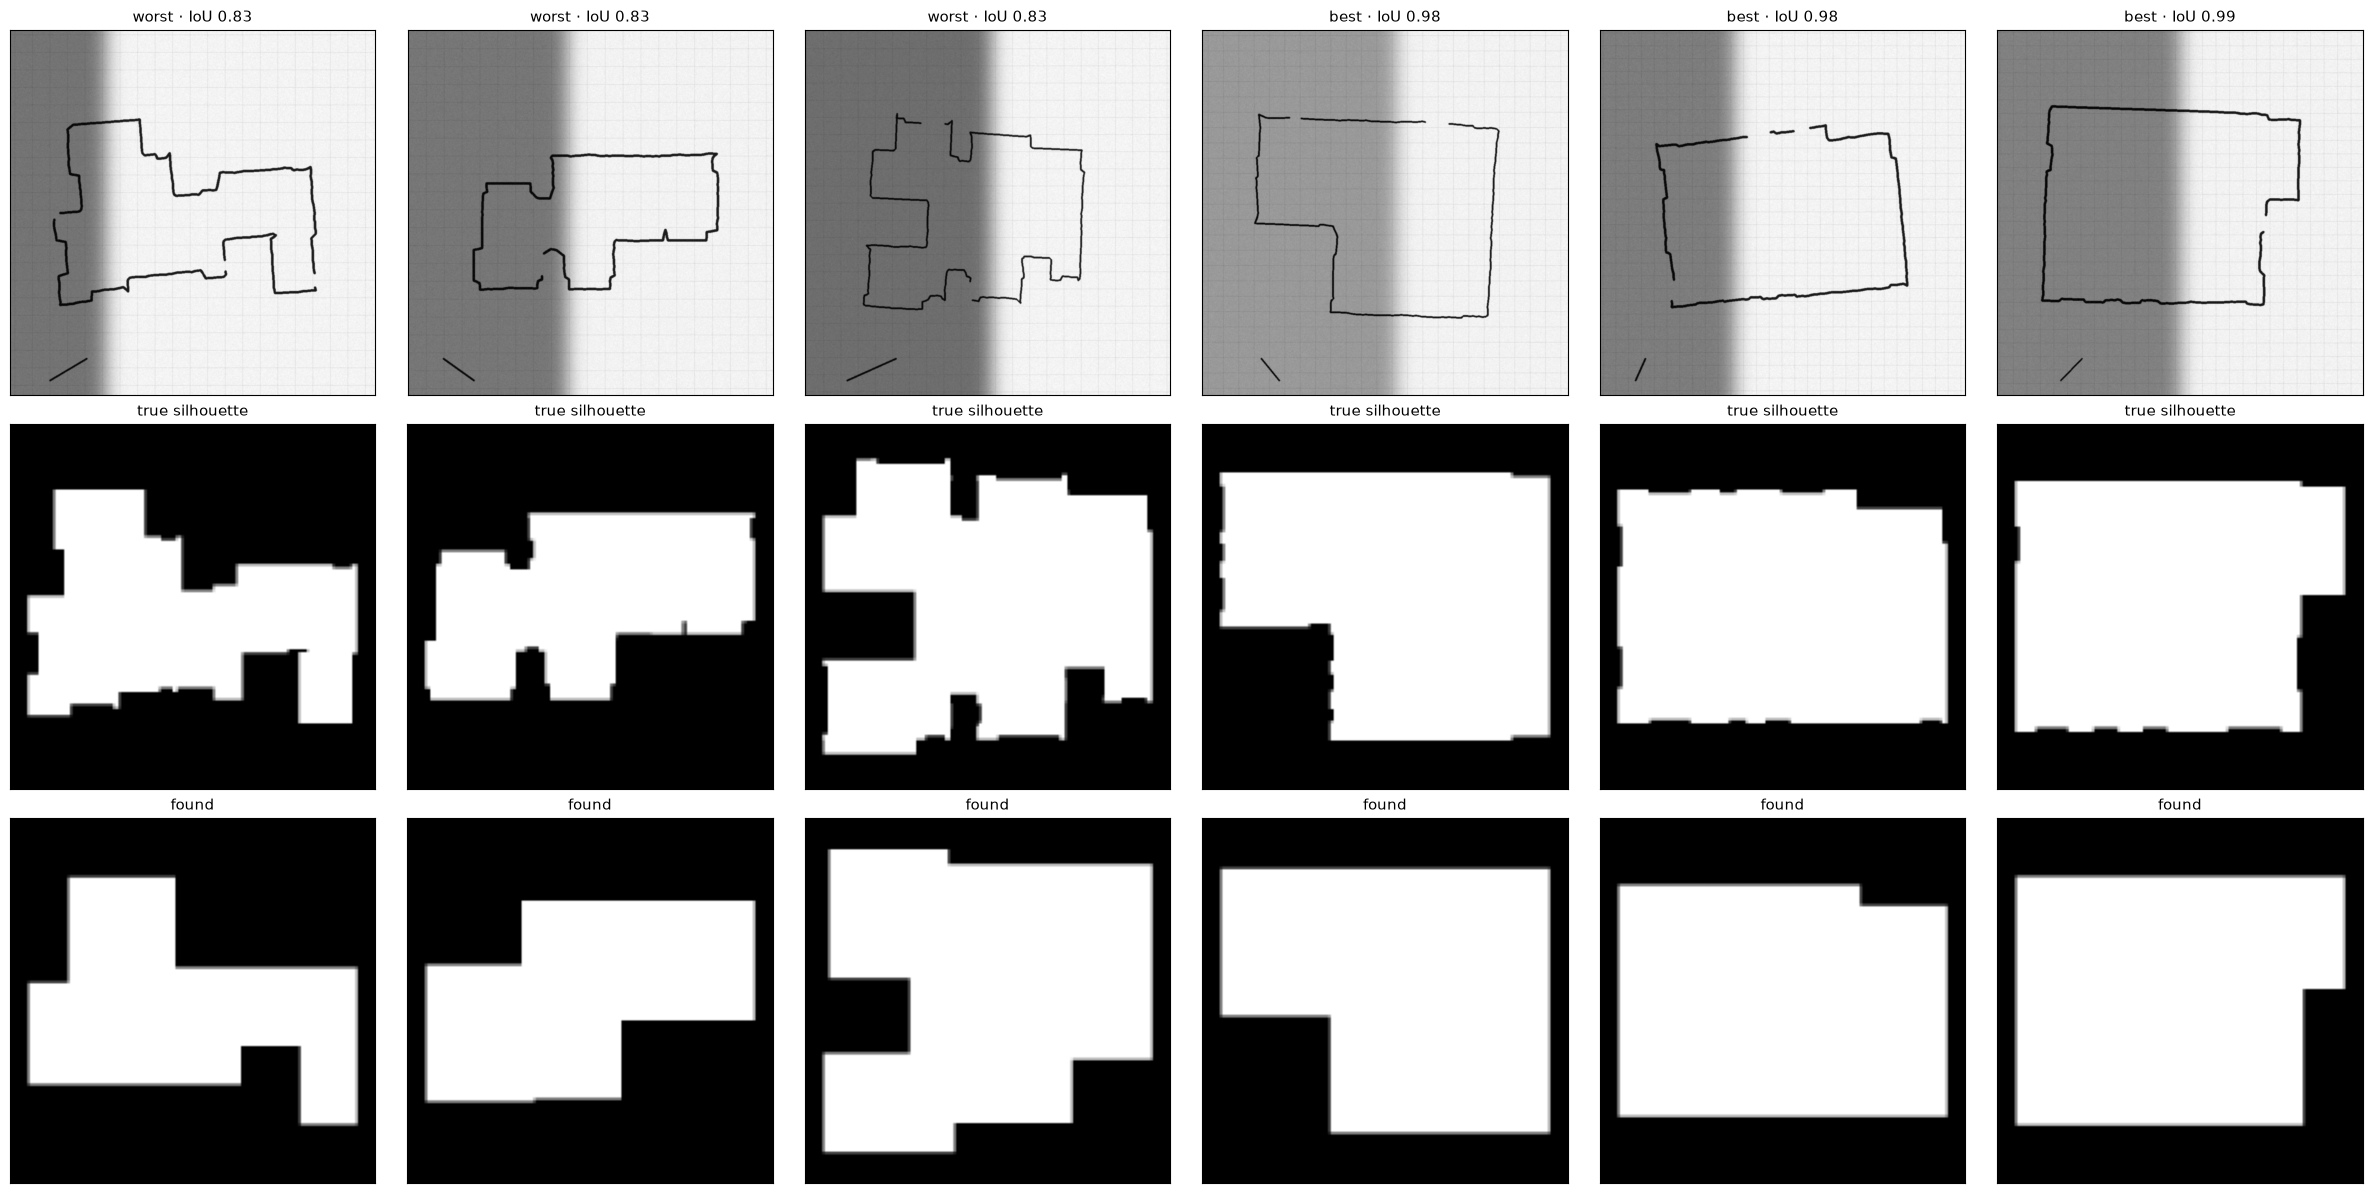

In [3]:
def fake_sketch(sil, rng, size=1000):
    # draw a silhouette like a hand sketch on squared paper
    m = (sil > 127).astype(np.uint8)
    c = max(cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0], key=cv2.contourArea)
    poly = cv2.approxPolyDP(c, 0.8, True)[:, 0, :].astype(float)
    t = np.radians(rng.uniform(-7, 7))
    turn = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
    p = (poly - 64) * rng.uniform(5.0, 6.5) @ turn.T + size / 2 + rng.uniform(-40, 40, 2)
    paper = np.full((size, size), 232, np.float32)
    step = int(rng.integers(35, 55))
    for x in range(int(rng.integers(0, step)), size, step):            # the grid
        paper[:, x] -= 28
        paper[x, :] -= 28
    pts = np.vstack([a + (b - a) * np.linspace(0, 1, max(2, int(np.hypot(*(b - a)) / 8)), endpoint=False)[:, None]
                     for a, b in zip(p, np.roll(p, -1, 0))])
    wobble = np.cumsum(rng.normal(0, 0.8, pts.shape), 0)
    pts = pts + np.clip(wobble - wobble.mean(0), -6, 6)                  # a crooked hand
    n, gaps = len(pts), set()
    for _ in range(rng.integers(1, 4)):                                    # gaps in the line
        s0 = rng.integers(0, n)
        gaps |= {(s0 + i) % n for i in range(rng.integers(3, 8))}
    width = int(rng.integers(3, 6))
    for i in range(n):
        if i not in gaps and (i + 1) % n not in gaps:
            a, b = np.round(pts[i]).astype(int), np.round(pts[(i + 1) % n]).astype(int)
            cv2.line(paper, tuple(int(v) for v in a), tuple(int(v) for v in b), 35, width)
    cv2.line(paper, (int(rng.integers(50, 300)), 960), (int(rng.integers(50, 300)), 900), 35, 4)   # a stray mark
    shade = np.ones((size, size), np.float32)
    shade[:, :int(rng.integers(200, 600))] = rng.uniform(0.45, 0.7)                                 # a shadow
    shade = cv2.GaussianBlur(shade, (0, 0), 25)
    photo = np.clip(paper * shade + rng.normal(0, 6, paper.shape), 0, 255).astype(np.uint8)
    return cv2.GaussianBlur(photo, (3, 3), 0)


def best_iou(found, true):
    # IoU allowing the 4 turns and a mirror
    a, best = true > 127, 0.0
    for k in range(4):
        for mirror in [False, True]:
            x = np.rot90(found, k)
            x = (np.fliplr(x) if mirror else x) > 127
            best = max(best, (a & x).sum() / max((a | x).sum(), 1))
    return best


rng = np.random.default_rng(7)
test_rows = rng.choice(val_rows, size=min(40, len(val_rows)), replace=False)
results, examples = [], []
for r in test_rows:
    photo = fake_sketch(sils[r], rng)
    start = time.time()
    found_corners = lc.photo_to_outline(lc.read_photo(cv2.imencode(".png", photo)[1].tobytes()))
    seconds = time.time() - start
    found = lc.silhouette_input(found_corners, 100)["sil_u8"] if found_corners is not None else None
    iou = best_iou(found, sils[r]) if found is not None else 0.0
    results.append({"plan": lib.loc[r, "id"], "shape found": found is not None, "IoU": iou, "seconds": seconds})
    examples.append((photo, found, sils[r], iou))
res = pd.DataFrame(results)
print(pd.Series({"shape found": res["shape found"].mean(), "IoU median": res["IoU"].median(),
                 "IoU >= 0.90": (res["IoU"] >= 0.9).mean(), "IoU >= 0.80": (res["IoU"] >= 0.8).mean(),
                 "seconds per photo": res["seconds"].mean()}).round(3).to_string())

order = np.argsort(res["IoU"].to_numpy())
fig, axes = plt.subplots(3, 6, figsize=(24, 12))
for col, k in enumerate(list(order[:3]) + list(order[-3:])):
    photo, found, true, iou = examples[k]
    axes[0, col].imshow(photo, cmap="gray"); axes[0, col].set_title(f"{'worst' if col < 3 else 'best'} · IoU {iou:.2f}", fontsize=11)
    axes[1, col].imshow(true, cmap="gray"); axes[1, col].set_title("true silhouette", fontsize=11)
    if found is not None:
        axes[2, col].imshow(found, cmap="gray")
    axes[2, col].set_title("found", fontsize=11)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
save_fig("61_photo_test")
plt.show()

### What to look at
- In how many sketches is a closed shape **found**? How close is it to the true silhouette?
- The worst cases: what goes wrong (a gap too big, a corner cut, a step lost)?

# 3. The whole app, end to end

Our sketch + what the user types: **95 m², 3 bedrooms, a balcony**. One call does everything: photo → silhouette → 30 pictures of the model → step 3 → 5 options.

2.7 s for the whole request | usable pictures: 5 of 30 | dropped: {'a bedroom is too small': 5, 'no kitchen': 6, 'cannot fit 3 bedrooms': 11, 'no bathroom': 1, 'balcony asked': 1, 'no living': 1}
Figure saved to ..\figures\62_app_end_to_end.png


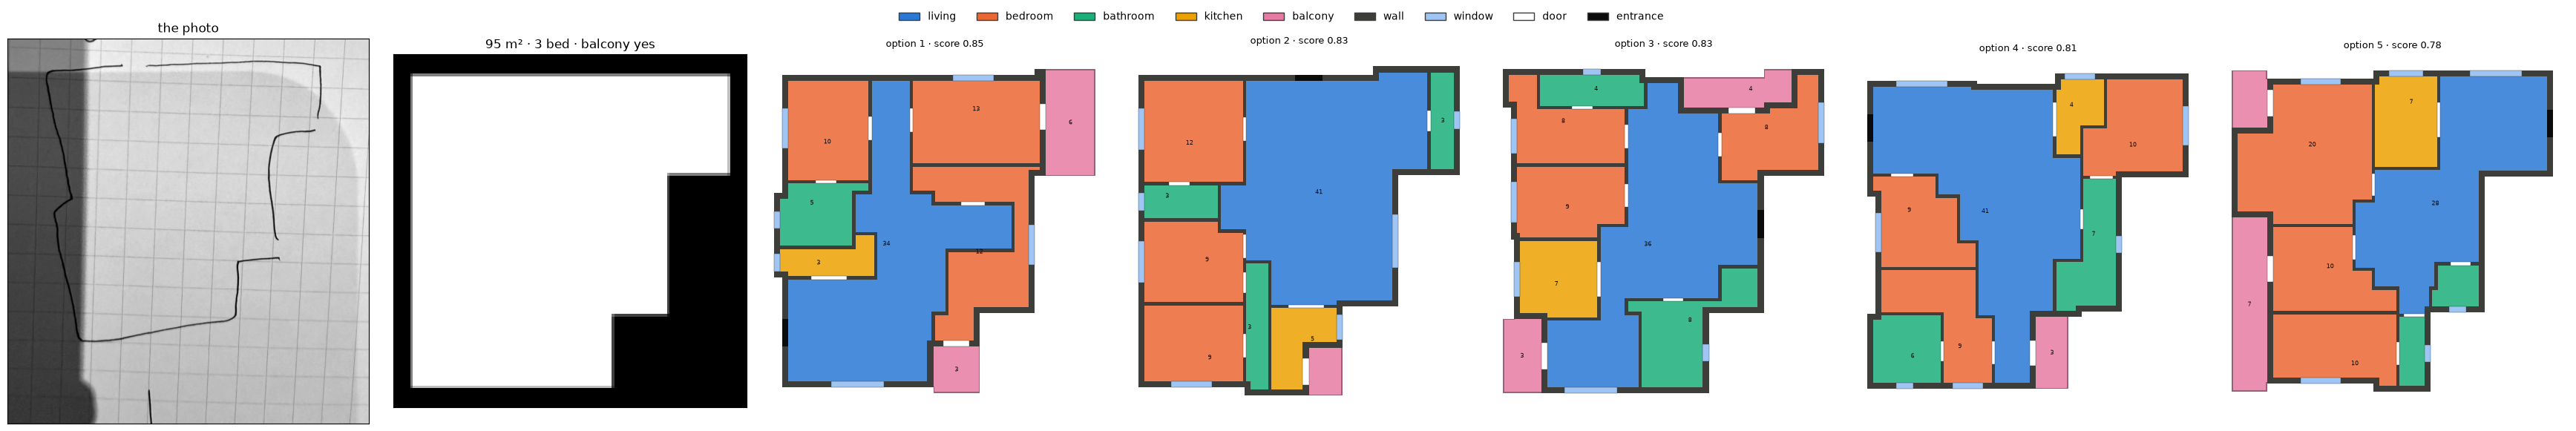

5 DXF files saved in ..\layout_examples


In [4]:
AREA_M2, BEDROOMS, BALCONY = 95, 3, 1

start = time.time()
result = lc.design_from_photo(model, SKETCH, AREA_M2, BEDROOMS, BALCONY, rules, AREA_MEAN, AREA_STD, device=DEVICE)
print(f"{time.time() - start:.1f} s for the whole request | usable pictures: {result['reasons'].get('ok', 0)} of 30 "
      f"| dropped: {dict((k, v) for k, v in result['reasons'].items() if k != 'ok')}")

options = result["options"]
fig, axes = plt.subplots(1, 7, figsize=(35, 5.5), gridspec_kw={"width_ratios": [1.1, 1, 1, 1, 1, 1, 1]})
axes[0].imshow(lc.read_photo(SKETCH), cmap="gray"); axes[0].set_title("the photo", fontsize=12)
axes[1].imshow(result["sil_u8"], cmap="gray")
axes[1].set_title(f"{AREA_M2} m² · {BEDROOMS} bed · balcony {'yes' if BALCONY else 'no'}", fontsize=12)
for ax in axes[:2]:
    ax.set_xticks([]); ax.set_yticks([])
for c in range(5):
    if c < len(options):
        lc.draw_layout(options[c], axes[c + 2], f"option {c + 1} · score {options[c]['score']:.2f}")
    else:
        axes[c + 2].set_axis_off()
fig.legend(handles=LEGEND, loc="upper center", ncol=len(LEGEND), frameon=False, bbox_to_anchor=(0.5, 1.06))
plt.tight_layout()
save_fig("62_app_end_to_end")
plt.show()

try:
    import ezdxf
    for k, option in enumerate(options, start=1):
        lc.export_dxf(option, EXAMPLES_DIR / f"sketch_option_{k}.dxf",
                      note=f"Team 4 - from the sketch - {AREA_M2} m2, {BEDROOMS} bedrooms - option {k}")
    print(f"{len(options)} DXF files saved in {EXAMPLES_DIR}")
except ImportError:
    print("ezdxf is not installed: no DXF")

### What to look at
- Do the 5 options **fill the drawn silhouette**, with 3 bedrooms and a balcony?
- Is the whole request fast enough for the app?
- Open one of the `sketch_option_*.dxf` files in AutoCAD or Rhino.

# 4. Your own photo

Draw a silhouette, take a photo, put it in `01_autoencoder/layout_examples/`, and fill in the cell. Photograph only the drawing (crop it if needed), from above, with the whole outline inside the photo.

In [5]:
MY_PHOTO = None              # e.g. EXAMPLES_DIR / "my_sketch.jpg"
MY_AREA_M2, MY_BEDROOMS, MY_BALCONY = 110, 3, 1

if MY_PHOTO is not None:
    mine = lc.design_from_photo(model, MY_PHOTO, MY_AREA_M2, MY_BEDROOMS, MY_BALCONY, rules, AREA_MEAN, AREA_STD, device=DEVICE)
    if mine.get("error"):
        print(mine["error"])
    else:
        fig, axes = plt.subplots(1, 6, figsize=(30, 5.5))
        axes[0].imshow(mine["sil_u8"], cmap="gray"); axes[0].set_xticks([]); axes[0].set_yticks([])
        for c, option in enumerate(mine["options"][:5]):
            lc.draw_layout(option, axes[c + 1], f"option {c + 1} · score {option['score']:.2f}")
        plt.tight_layout()
        plt.show()
else:
    print("no photo yet: fill in MY_PHOTO")

no photo yet: fill in MY_PHOTO


# 5. The fallback: tap the corners

When no closed shape is found (a very messy drawing, a big gap), the app shows the photo and the user **taps the corners in order**. The taps are squared the same way. Here we pretend: the corners found in section 1, moved by up to 8 pixels (a finger is not exact).

In [6]:
taps = dbg["approx"] + np.random.default_rng(0).normal(0, 8, dbg["approx"].shape)      # pixels, y down, like a screen
tapped = lc.outline_from_taps(taps)
fallback = lc.design_from_outline(model, tapped, AREA_M2, BEDROOMS, BALCONY, rules, AREA_MEAN, AREA_STD, device=DEVICE)
print(f"{len(taps)} taps -> {len(tapped)} squared corners -> {len(fallback['options'])} options "
      f"(IoU with section 1: {best_iou(fallback['sil_u8'], inp['sil_u8']):.3f})")

8 taps -> 8 squared corners -> 5 options (IoU with section 1: 0.970)
